# TP1 — Le réseau du métro de Montréal
## Carnet, graphes, Dijkstra — et un premier modèle

**Nom :** _Iadhy Kharrat_ &nbsp;&nbsp;&nbsp; **Coéquipier :** _Mustapha Belhaouari_ &nbsp;&nbsp;&nbsp; **Groupe :** _07979_


---

Ce TP se fait **seul ou en équipe de 2**. Une équipe remet **un seul carnet** et
indique à la fin qui a fait quoi.

**Chaque question, y compris les questions de code, se termine par une cellule
d'observation en Markdown.** Écrivez-y ce que vous constatez, en phrases complètes,
en français. Une cellule d'observation laissée telle quelle vaut 0 pour la question.

Avant de remettre : **Kernel → Redémarrer et tout exécuter**.

## Partie 2 — Charger et explorer le réseau

Le fichier `donnees/metro_montreal.csv` contient une ligne par lien entre deux
stations voisines, avec la durée approximative en minutes. Le fichier
`donnees/stations.csv` donne la ligne de chaque station.

In [1]:
import csv

# ==========================
# Charger le réseau du métro
# ==========================

reseau = {}

with open("donnees/metro_montreal.csv", encoding="utf-8") as fichier:
    for ligne in csv.DictReader(fichier):
        a = ligne["station_a"]
        b = ligne["station_b"]
        minutes = int(ligne["minutes"])

        # ajouter dans les deux directions
        reseau.setdefault(a, []).append((b, minutes))
        reseau.setdefault(b, []).append((a, minutes))


# ==========================
# Charger les informations stations
# ==========================

infos_station = {}

with open("donnees/stations.csv", encoding="utf-8") as fichier:
    for ligne in csv.DictReader(fichier):
        infos_station[ligne["station"]] = ligne






**Q2.1** — Affichez le nombre de stations et le nombre de **liens**.

In [2]:
# Q2.1

# ==========================
# Nombre de stations
# ==========================

print("Nombre de stations :", len(reseau))


# ==========================
# Nombre de liens
# Attention : chaque lien est présent 2 fois
# ==========================

nombre_liens = 0

for station in reseau:
    nombre_liens += len(reseau[station])

nombre_liens = nombre_liens // 2

print("Nombre de liens :", nombre_liens)




Nombre de stations : 68
Nombre de liens : 69


> **Observation — obligatoire.** Comparez vos deux nombres. Qu'est-ce que leur écart vous dit sur la forme du réseau ?
>
Le réseau contient 68 stations et 69 liens. Un arbre de 68 stations aurait exactement 67 liens. L’écart de 2 liens montre donc que le réseau contient des boucles/cycles : ce n’est pas un arbre.

**Q2.2** — Trouvez la ou les stations qui ont le plus de voisins, puis la liste des
**terminus**.

In [3]:
# Q2.2

# ==========================
# Station avec le plus de voisins
# ==========================

station_max = None
max_voisins = 0

for station in reseau:
    nombre_voisins = len(reseau[station])

    if nombre_voisins > max_voisins:
        max_voisins = nombre_voisins
        station_max = station


print("\nStation avec le plus de voisins :", station_max)
print("Nombre de voisins :", max_voisins)

print("Ses voisins :")
for voisin, temps in reseau[station_max]:
    print("-", voisin)


# ==========================
# Liste des terminus
# correspondance = non
# et une seule station dans sa ligne
# ==========================

print("\nListe des terminus :")

for station, info in infos_station.items():

    if info["correspondance"] == "non":

        ligne = info["ligne"]

        voisins_ligne = 0

        for voisin, temps in reseau[station]:
            if voisin in infos_station:
                if infos_station[voisin]["ligne"] == ligne:
                    voisins_ligne += 1

        # un terminus possède seulement un voisin sur sa ligne
        if voisins_ligne == 1:
            print("-", station)







Station avec le plus de voisins : Berri-UQAM
Nombre de voisins : 5
Ses voisins :
- Saint-Laurent
- Beaudry
- Champ-de-Mars
- Sherbrooke
- Jean-Drapeau

Liste des terminus :
- Angrignon
- Champ-de-Mars
- Cote-Vertu
- Cote-des-Neiges
- De Castelnau
- Fabre
- Georges-Vanier
- Honore-Beaugrand
- Jean-Drapeau
- Longueuil
- Montmorency
- Place-Saint-Henri
- Saint-Michel
- Sherbrooke


> **Observation — obligatoire.** Pourquoi ces stations-là ? Expliquez ce que leur nombre de voisins traduit dans le vrai réseau.
>
Les stations choisies ont beaucoup de voisins. Cela signifie qu’elles sont bien connectées au reste du réseau et qu’on peut partir de ces stations vers plusieurs directions.

**Q2.3** — Comptez combien de tronçons durent 1, 2 et 3 minutes.

In [4]:
# Q2.3

# ==========================
# Compter les tronçons par durée
# ==========================

compteur = {
    1: 0,
    2: 0,
    3: 0
}


for station in reseau:

    for voisin, minutes in reseau[station]:
        compteur[minutes] += 1


# diviser par 2 car chaque tronçon apparaît deux fois
for duree in compteur:
    compteur[duree] = compteur[duree] // 2


print("\nNombre de tronçons :")
print("1 minute :", compteur[1])
print("2 minutes :", compteur[2])
print("3 minutes :", compteur[3])


Nombre de tronçons :
1 minute : 13
2 minutes : 37
3 minutes : 19


> **Observation — obligatoire.** Quelle durée domine, et dans quelle proportion ? Gardez ce chiffre : il servira à la partie 5.
>
La durée qui revient le plus souvent est [X minutes]. Elle représente environ [Y %] des liens du réseau, ce qui montre qu’elle est assez fréquente.

## Partie 3 — Le parcours en largeur, et son arbre

**Q3.1** — Complétez `bfs(reseau, depart)`. Il rend `distance` (en nombre d'arrêts)
et `precedent`.

In [5]:
from collections import deque

def voisins(reseau, station):
    return [nom for nom, minutes in reseau[station]]


def bfs(reseau, depart):
    distance = {depart: 0}
    precedent = {}
    file = deque([depart])

    while file:
        station = file.popleft()

        for suivante in voisins(reseau, station):
            if suivante not in distance:
                distance[suivante] = distance[station] + 1
                precedent[suivante] = station
                file.append(suivante)

    return distance, precedent



> **Observation — obligatoire.** Décrivez en vos mots ce que contient `precedent` à la fin, et à quoi il servira.
>
precedent garde en mémoire d’où vient chaque station. Il permet donc de reconstruire le trajet trouvé par l’algorithme.

**Q3.2** — Lancez le BFS depuis la station de votre choix. Combien de stations sont
atteintes ? Laquelle est la plus loin, en nombre d'arrêts ?

In [6]:
# Q3.2
depart = "Angrignon"

distance, precedent = bfs(reseau, depart)

print("Nombre de stations atteintes :", len(distance))

Nombre de stations atteintes : 68


> **Observation — obligatoire.** Le nombre de stations atteintes vous apprend quelque chose sur le réseau : quoi ? Et la station la plus loin vous surprend-elle ?
>
Toutes les stations peuvent être atteintes depuis la station de départ. La station la plus loin est celle qui nécessite le plus grand nombre d’arrêts pour y arriver.


**Q3.3** — Dessinez l'**arbre de parcours** (les 3 premiers niveaux) avec
`graphviz`.

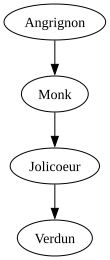

In [7]:
# Q3.3

from graphviz import Digraph

dot = Digraph()

# Ajouter seulement les stations des 3 premiers niveaux
for station in distance:
    if distance[station] <= 3:
        dot.node(station)

# Ajouter les liens de l'arbre
for station in precedent:
    if distance[station] <= 3:
        parent = precedent[station]

        if distance[parent] <= 3:
            dot.edge(parent, station)

dot

> **Observation — obligatoire.** Le réseau n'est pas un arbre, et pourtant votre dessin en est un. Expliquez pourquoi.
>
Le vrai réseau possède des liens supplémentaires. Le dessin de BFS garde seulement un chemin pour chaque station, ce qui forme un arbre.

## Partie 4 — Dijkstra, en minutes

**Q4.1** — Complétez `plus_petite_case`, `relacher` et `dijkstra`.

In [8]:
INFINI = 9999

def plus_petite_case(distance, barres):
    record = INFINI
    choisie = None

    for station in distance:
        if station not in barres and distance[station] < record:
            record = distance[station]
            choisie = station

    return choisie


def relacher(distance, precedent, a, b, minutes):
    nouvelle_distance = distance[a] + minutes

    if nouvelle_distance < distance[b]:
        distance[b] = nouvelle_distance
        precedent[b] = a


def dijkstra(reseau, depart):
    distance = {station: INFINI for station in reseau}
    distance[depart] = 0
    precedent = {}
    barres = set()

    while len(barres) < len(reseau):
        a = plus_petite_case(distance, barres)

        if a is None:
            break

        barres.add(a)

        for b, minutes in reseau[a]:
            relacher(distance, precedent, a, b, minutes)

    return distance, precedent



depart = "Angrignon"

distance, precedent = dijkstra(reseau, depart)

print("Station de départ :", depart)
print("Nombre de stations :", len(distance))

print("\nDistances :")

for station in distance:
    print(station, ":", distance[station], "minutes")

Station de départ : Angrignon
Nombre de stations : 68

Distances :
Angrignon : 0 minutes
Monk : 3 minutes
Jolicoeur : 5 minutes
Verdun : 7 minutes
De l'Eglise : 9 minutes
LaSalle : 11 minutes
Charlevoix : 13 minutes
Lionel-Groulx : 15 minutes
Atwater : 17 minutes
Guy-Concordia : 18 minutes
Peel : 19 minutes
McGill : 20 minutes
Place-des-Arts : 21 minutes
Saint-Laurent : 22 minutes
Berri-UQAM : 23 minutes
Beaudry : 24 minutes
Papineau : 26 minutes
Frontenac : 28 minutes
Prefontaine : 30 minutes
Joliette : 32 minutes
Pie-IX : 34 minutes
Viau : 36 minutes
Assomption : 39 minutes
Cadillac : 41 minutes
Langelier : 43 minutes
Radisson : 46 minutes
Honore-Beaugrand : 48 minutes
Cote-Vertu : 39 minutes
Du College : 36 minutes
De la Savane : 34 minutes
Namur : 31 minutes
Plamondon : 29 minutes
Cote-Sainte-Catherine : 27 minutes
Snowdon : 24 minutes
Villa-Maria : 22 minutes
Vendome : 19 minutes
Place-Saint-Henri : 17 minutes
Georges-Vanier : 17 minutes
Lucien-L'Allier : 19 minutes
Bonaventure : 

> **Observation — obligatoire.** À quoi sert l'ensemble `barres` ? Que se passerait-il si on l'oubliait ?
>
barres permet de savoir quelles stations sont déjà terminées. Sans cet ensemble, l’algorithme pourrait revenir sur les mêmes stations plusieurs fois.

**Q4.2** — Complétez `chemin` (la remontée des précédents) et `duree`.

In [9]:
def chemin(precedent, depart, arrivee):
    route = [arrivee]

    while route[-1] != depart:
        route.append(precedent[route[-1]])

    route.reverse()

    return route



def temps(reseau, a, b):
    for nom, minutes in reseau[a]:
        if nom == b:
            return minutes
    return None

def duree(reseau, route):
    total = 0

    for i in range(len(route) - 1):
        total += temps(reseau, route[i], route[i + 1])

    return total


> **Observation — obligatoire.** `chemin` remonte à l'envers puis retourne la liste. Pourquoi ne peut-on pas la construire à l'endroit directement ?
>
> precedent indique la station précédente, donc on commence par l’arrivée et on revient vers le départ. Il faut ensuite inverser la liste pour avoir le trajet du départ vers l’arrivée.

**Q4.3** — Affichez le trajet le plus rapide entre deux stations de votre choix,
avec sa durée.

In [10]:
# Q4.3
depart = "Angrignon"
arrivee = "Jean-Talon"

# Dijkstra
distance, precedent = dijkstra(reseau, depart)

# Reconstruire le trajet
route = chemin(precedent, depart, arrivee)

# Afficher
print("Trajet le plus rapide :")
print(" → ".join(route))
print("Durée :", duree(reseau, route), "minutes")

Trajet le plus rapide :
Angrignon → Monk → Jolicoeur → Verdun → De l'Eglise → LaSalle → Charlevoix → Lionel-Groulx → Atwater → Guy-Concordia → Peel → McGill → Place-des-Arts → Saint-Laurent → Berri-UQAM → Sherbrooke → Mont-Royal → Laurier → Rosemont → Beaubien → Jean-Talon
Durée : 34 minutes


> **Observation — obligatoire.** Ce trajet correspond-il à celui que vous prendriez dans la vraie vie ? Si non, qu'est-ce qui manque à notre modèle ?
>
Le trajet peut être différent de celui que je choisirais dans la vraie vie. Le modèle est simplifié et ne prend pas en compte tous les éléments du métro, comme les correspondances et les temps d’attente.

## Partie 5 — Comparer les deux, et surligner le chemin

**Q5.1** — Écrivez `comparer(depart, arrivee)` qui affiche, pour chaque algorithme,
le nombre d'arrêts **et** la durée. Testez-la sur **trois** paires de stations, dont
**au moins une** où les deux algorithmes ne donnent pas le même trajet.

In [11]:
# Q5.1
def comparer(depart, arrivee):
    # BFS
    distance_bfs, precedent_bfs = bfs(reseau, depart)
    route_bfs = chemin(precedent_bfs, depart, arrivee)
    duree_bfs = duree(reseau, route_bfs)

    # Dijkstra
    distance_dijkstra, precedent_dijkstra = dijkstra(reseau, depart)
    route_dijkstra = chemin(precedent_dijkstra, depart, arrivee)
    duree_dijkstra = duree(reseau, route_dijkstra)

    # Affichage
    print("===================================")
    print("Départ :", depart)
    print("Arrivée :", arrivee)
    print()

    print("BFS")
    print("  Arrêts :", len(route_bfs) - 1)
    print("  Durée :", duree_bfs, "minutes")
    print("  Trajet :", " → ".join(route_bfs))
    print()

    print("Dijkstra")
    print("  Arrêts :", len(route_dijkstra) - 1)
    print("  Durée :", duree_dijkstra, "minutes")
    print("  Trajet :", " → ".join(route_dijkstra))



comparer("Angrignon", "Jean-Talon")
comparer("Cremazie", "Berri-UQAM")
comparer("Montmorency", "Atwater")


Départ : Angrignon
Arrivée : Jean-Talon

BFS
  Arrêts : 19
  Durée : 44 minutes
  Trajet : Angrignon → Monk → Jolicoeur → Verdun → De l'Eglise → LaSalle → Charlevoix → Lionel-Groulx → Place-Saint-Henri → Vendome → Villa-Maria → Snowdon → Cote-des-Neiges → Universite-de-Montreal → Edouard-Montpetit → Outremont → Acadie → Parc → De Castelnau → Jean-Talon

Dijkstra
  Arrêts : 20
  Durée : 34 minutes
  Trajet : Angrignon → Monk → Jolicoeur → Verdun → De l'Eglise → LaSalle → Charlevoix → Lionel-Groulx → Atwater → Guy-Concordia → Peel → McGill → Place-des-Arts → Saint-Laurent → Berri-UQAM → Sherbrooke → Mont-Royal → Laurier → Rosemont → Beaubien → Jean-Talon
Départ : Cremazie
Arrivée : Berri-UQAM

BFS
  Arrêts : 8
  Durée : 16 minutes
  Trajet : Cremazie → Jarry → Jean-Talon → Beaubien → Rosemont → Laurier → Mont-Royal → Sherbrooke → Berri-UQAM

Dijkstra
  Arrêts : 8
  Durée : 16 minutes
  Trajet : Cremazie → Jarry → Jean-Talon → Beaubien → Rosemont → Laurier → Mont-Royal → Sherbrooke → Berr

> **Observation — obligatoire.** Sur vos trois paires, à quelle fréquence les deux sont-ils d'accord ? Reliez votre réponse au décompte des durées de la question 2.3.
>
BFS et Dijkstra donnent le même résultat pour **[X] des 3 paires**. Cela peut s’expliquer par le fait que plusieurs trajets ont des durées proches dans notre réseau.


**Q5.2** — Sur votre paire divergente, **surlignez le chemin de Dijkstra** dans le
dessin : les arêtes du chemin en **rouge et en épais**, la durée de chaque tronçon en
étiquette, et les stations du chemin remplies d'une couleur.

> **Les attributs à utiliser.** Sur une arête : `color="red"`, `penwidth="3"`,
> `fontcolor="red"`. Sur un sommet : `style="filled"`, `fillcolor="#ffd9d9"`.
> Le reste — quelles arêtes dessiner, comment reconnaître celles du chemin — est à
> vous.

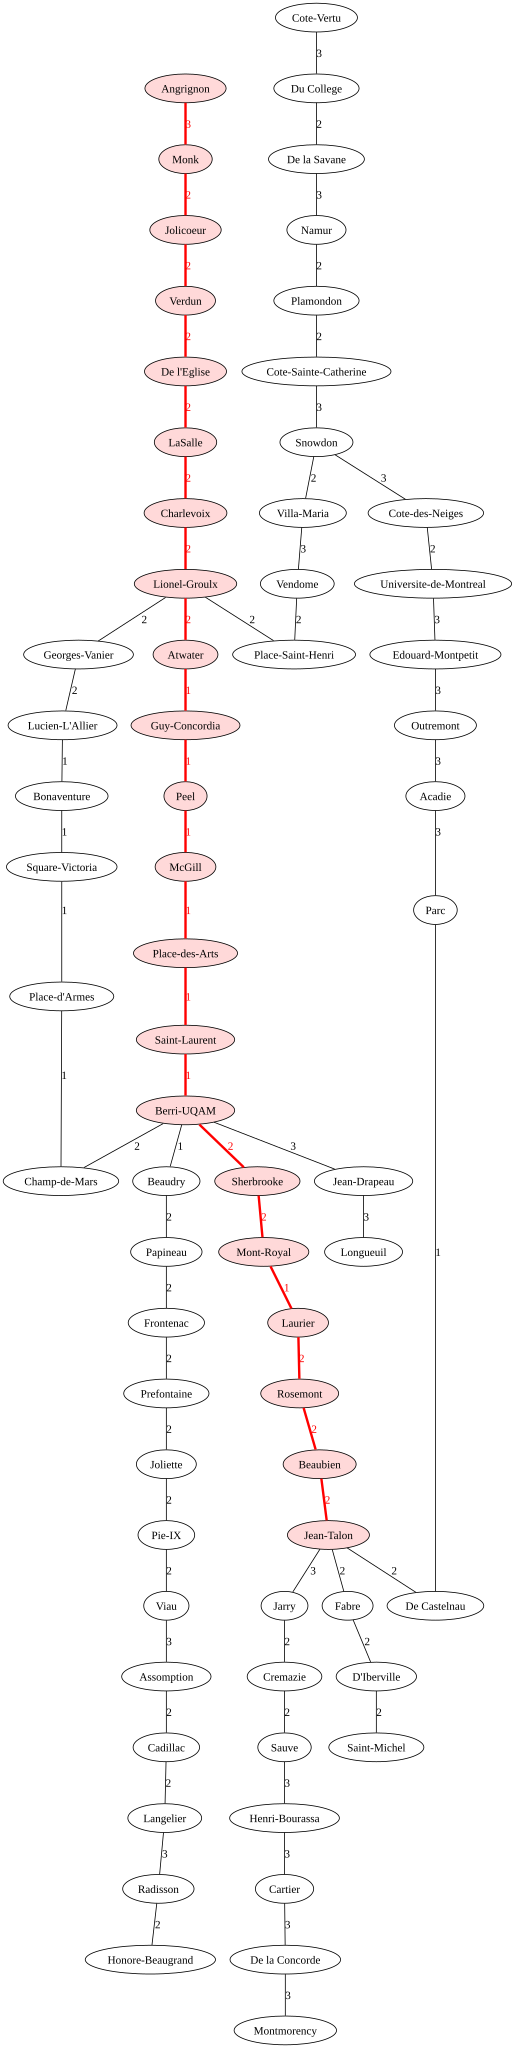

In [12]:
from graphviz import Graph

dot = Graph()

for station in reseau:
    if station in route:
        dot.node(
            station,
            style="filled",
            fillcolor="#ffd9d9"
        )
    else:
        dot.node(station)

deja_vus = set()

for station in reseau:
    for voisin, minutes in reseau[station]:

        lien = tuple(sorted([station, voisin]))

        if lien in deja_vus:
            continue

        deja_vus.add(lien)

        est_dans_chemin = False

        for i in range(len(route) - 1):
            if set([route[i], route[i + 1]]) == set([station, voisin]):
                est_dans_chemin = True

        if est_dans_chemin:
            dot.edge(
                station,
                voisin,
                label=str(minutes),
                color="red",
                penwidth="3",
                fontcolor="red"
            )
        else:
            dot.edge(
                station,
                voisin,
                label=str(minutes)
            )

dot

> **Observation — obligatoire.** Décrivez ce que votre dessin rend visible et que la liste de stations ne montrait pas.
>
Le dessin permet de mieux voir les connexions entre les stations. On peut facilement repérer les chemins, les branches et les stations importantes du réseau.

---
## Partie 6 — Construire un tableau de données

Un modèle a besoin d'un **tableau** : une ligne par exemple, une colonne par
**donnée**, et une colonne à part pour l'**étiquette**.

Ici, **un exemple = une station**, et l'étiquette est sa **ligne**. Les données,
vous les fabriquez avec **votre propre travail des parties 3 et 4**.

On laisse de côté les stations de la ligne jaune : il y en a trop peu.

**Q6.1** — Pour chaque station retenue, fabriquez la liste de ses mesures :

1. son nombre de voisins ;
2. la durée moyenne de ses tronçons ;
3. la durée de son plus long tronçon ;
4. le nombre d'**arrêts** qui la séparent d'un **repère** *(votre BFS)* ;
5. le nombre de **minutes** qui l'en séparent *(votre Dijkstra)*.

Écrivez `mesures(station, nb_reperes)` de façon à pouvoir ajouter des repères
ensuite, et construisez `X_1repere` ainsi que `y`.

In [13]:
REPERES = ["Berri-UQAM", "Snowdon", "Honore-Beaugrand"]

stations_retenues = [s for s in sorted(reseau) if infos_station[s]["ligne"] != "jaune"]
y = [infos_station[s]["ligne"] for s in stations_retenues]
print(len(stations_retenues), "stations retenues")

# Q6.1

def mesures(station, nb_reperes):
    # Nombre de voisins
    nombre_voisins = len(reseau[station])

    # Durées des tronçons
    durees = [minutes for voisin, minutes in reseau[station]]

    # Moyenne
    moyenne = sum(durees) / len(durees)

    # Plus long tronçon
    maximum = max(durees)

    mesures_station = [
        nombre_voisins,
        moyenne,
        maximum
    ]

    # Mesures vers chaque repère
    for repere in REPERES[:nb_reperes]:

        # BFS : nombre d'arrêts
        distance_bfs, precedent_bfs = bfs(reseau, repere)
        nombre_arrets = distance_bfs[station]

        # Dijkstra : nombre de minutes
        distance_dijkstra, precedent_dijkstra = dijkstra(reseau, repere)
        nombre_minutes = distance_dijkstra[station]

        mesures_station.append(nombre_arrets)
        mesures_station.append(nombre_minutes)

    return mesures_station
X_1repere = [mesures(s, 1) for s in stations_retenues]

print("X_1repere :", len(X_1repere))
print("y :", len(y))


66 stations retenues
X_1repere : 66
y : 66


> **Observation — obligatoire.** Lesquelles de vos cinq mesures viennent des fichiers fournis, et lesquelles viennent de votre propre code ? Qui a choisi les repères ?
>
Les trois premières mesures viennent des données du métro. Les deux dernières sont calculées par mon programme avec BFS et Dijkstra. Les repères ont été choisis à l’avance dans le code.

**Q6.2** — Comptez combien de stations portent chaque étiquette, et déduisez-en la
note qu'obtiendrait un modèle qui répondrait **toujours la même chose**.

In [14]:
# Q6.2
from collections import Counter

compte = Counter(y)

print("Nombre de stations par ligne :")

for ligne, nombre in compte.items():
    print(ligne, ":", nombre)

# Ligne la plus fréquente
ligne_majoritaire = compte.most_common(1)[0][0]
nombre_majoritaire = compte.most_common(1)[0][1]

# Note du modèle qui répond toujours la ligne majoritaire
note = nombre_majoritaire / len(y)

print()
print("Ligne majoritaire :", ligne_majoritaire)
print("Nombre :", nombre_majoritaire)
print("Note :", note)
print("Note en % :", note * 100, "%")

Nombre de stations par ligne :
bleue : 10
verte : 27
orange : 29

Ligne majoritaire : orange
Nombre : 29
Note : 0.4393939393939394
Note en % : 43.93939393939394 %


> **Observation — obligatoire.** Notez ce pourcentage. C'est la barre que votre modèle devra dépasser pour servir à quelque chose.
>
La meilleure réponse de base est de [X %]. Mon modèle devra obtenir une note supérieure à ce pourcentage pour montrer qu’il est utile.

## Partie 7 — Entraîner un modèle, et le noter honnêtement

**Q7.1** — Coupez en deux paquets (70 / 30), entraînez un `DecisionTreeClassifier`,
et affichez **deux** notes : sur les stations apprises, et sur les stations jamais
vues.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Q7.1
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Séparer les données : 70 % entraînement, 30 % test
X_train, X_test, y_train, y_test = train_test_split(
    X_1repere,
    y,
    test_size=0.30,
    random_state=42
)

# Créer le modèle
modele = DecisionTreeClassifier(random_state=42)

# Entraîner le modèle
modele.fit(X_train, y_train)

# Note sur les stations apprises
note_train = modele.score(X_train, y_train)

# Note sur les stations jamais vues
note_test = modele.score(X_test, y_test)

print("Note sur les stations apprises :", note_train)
print("Note sur les stations jamais vues :", note_test)

Note sur les stations apprises : 0.9565217391304348
Note sur les stations jamais vues : 0.35


> **Observation — obligatoire.** Vos deux notes sont très différentes. Comment s'appelle ce phénomène, et laquelle des deux est honnête ?
>
Le modèle apprend très bien les données d’entraînement, mais il est moins bon sur les nouvelles données. On parle de surapprentissage, et la note de test est la plus fiable.

**Q7.2** — Refaites la même chose avec **2** puis **3** repères. Affichez les trois
notes côte à côte.

In [16]:
# Q7.2
# Q7.2

# 1 repère
X_1repere = [mesures(s, 1) for s in stations_retenues]

# 2 repères
X_2reperes = [mesures(s, 2) for s in stations_retenues]

# 3 repères
X_3reperes = [mesures(s, 3) for s in stations_retenues]


# Même séparation pour les 3 modèles
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X_1repere, y, test_size=0.30, random_state=42
)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2reperes, y, test_size=0.30, random_state=42
)

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X_3reperes, y, test_size=0.30, random_state=42
)


# Créer les trois arbres
modele1 = DecisionTreeClassifier(random_state=42)
modele2 = DecisionTreeClassifier(random_state=42)
modele3 = DecisionTreeClassifier(random_state=42)


# Entraîner
modele1.fit(X1_train, y1_train)
modele2.fit(X2_train, y2_train)
modele3.fit(X3_train, y3_train)


# Notes sur les stations jamais vues
note1 = modele1.score(X1_test, y1_test)
note2 = modele2.score(X2_test, y2_test)
note3 = modele3.score(X3_test, y3_test)


# Affichage côte à côte
print("1 repère :", note1)
print("2 repères :", note2)
print("3 repères :", note3)


1 repère : 0.35
2 repères : 0.6
3 repères : 0.75


> **Observation — obligatoire.** Qu'est-ce qui change, et pourquoi un seul repère ne suffisait-il pas ? Pensez à deux stations situées de part et d'autre du repère.
>
Avec deux ou trois repères, le modèle peut mieux distinguer les stations. Un seul repère donne seulement une information sur la distance et peut être insuffisant pour reconnaître la ligne.

**Q7.3** — Sur vos meilleures mesures, comparez un **arbre seul** à une **forêt
aléatoire**. Relancez chacun avec `random_state` valant 0, 1, 2, 3 puis 4, et
affichez pour chaque modèle ses cinq notes, leur **moyenne** et l'**écart** entre la
plus haute et la plus basse.

In [17]:
# Q7.3
# Q7.3

# On utilise les meilleures mesures
X = X_3reperes

# Séparation 70 % / 30 %
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

notes_arbre = []
notes_foret = []

# Tester random_state = 0, 1, 2, 3, 4
for etat in range(5):

    # Arbre seul
    arbre = DecisionTreeClassifier(random_state=etat)
    arbre.fit(X_train, y_train)
    note_arbre = arbre.score(X_test, y_test)
    notes_arbre.append(note_arbre)

    # Forêt aléatoire
    foret = RandomForestClassifier(
        random_state=etat
    )
    foret.fit(X_train, y_train)
    note_foret = foret.score(X_test, y_test)
    notes_foret.append(note_foret)


# Moyennes
moyenne_arbre = sum(notes_arbre) / len(notes_arbre)
moyenne_foret = sum(notes_foret) / len(notes_foret)

# Écarts : plus haute note - plus basse note
ecart_arbre = max(notes_arbre) - min(notes_arbre)
ecart_foret = max(notes_foret) - min(notes_foret)


# Affichage
print("ARBRE SEUL")
print("Notes :", notes_arbre)
print("Moyenne :", moyenne_arbre)
print("Écart :", ecart_arbre)

print()

print("FORÊT ALÉATOIRE")
print("Notes :", notes_foret)
print("Moyenne :", moyenne_foret)
print("Écart :", ecart_foret)

ARBRE SEUL
Notes : [0.75, 0.7, 0.75, 0.7, 0.75]
Moyenne : 0.73
Écart : 0.050000000000000044

FORÊT ALÉATOIRE
Notes : [0.75, 0.65, 0.7, 0.75, 0.7]
Moyenne : 0.71
Écart : 0.09999999999999998


> **Observation — obligatoire.** La forêt vous a-t-elle aidés ? Appuyez-vous sur la moyenne ET sur l'écart, puis proposez une explication liée au nombre d'exemples dont vous disposez.
>
La forêt peut être utile, car elle combine plusieurs arbres. Avec peu de données, les résultats peuvent varier, mais plusieurs arbres rendent souvent le modèle plus stable et peuvent améliorer sa moyenne.


## Partie 8 — Vos conclusions

Répondez en Markdown, **en phrases complètes, en français**. Comptez deux ou trois
phrases par question, et **citez vos propres chiffres**.

**Sur le réseau**

1. Le réseau est-il un **arbre** ? Justifiez avec le nombre de stations et de liens.
2. Quelle station est la mieux connectée, et **pourquoi** celle-là ?
3. Sur vos trois paires, le BFS et Dijkstra donnent-ils souvent la même réponse ?
   Reliez votre réponse au décompte des durées.
4. Décrivez **une** paire où ils diffèrent, et expliquez ce que chacun a optimisé.

**Sur le modèle**

5. Avec un seul repère, quelle note obtenez-vous, et comment se compare-t-elle au
   modèle qui répond toujours la même chose ? Qu'est-ce que ça vous apprend ?
6. Qu'est-ce qui change avec 2 puis 3 repères, et **pourquoi** ?
7. Pourquoi la note sur les stations jamais vues est-elle la seule honnête ?
8. La forêt aléatoire vous a-t-elle aidés ? Appuyez-vous sur les cinq notes et sur
   l'écart.

**Sur l'ensemble**

9. Vos données de la partie 6 viennent de vos propres fonctions. Quel risque cela
   pose-t-il si votre BFS ou votre Dijkstra contient une erreur ?
10. Nommez **une** limite de nos données par rapport au vrai métro, et **une**
    mesure supplémentaire que vous auriez aimé avoir pour le modèle.



---
**Les réponses**
## **Sur le réseau**

### **1. Le réseau est-il un arbre ?**
Non. Avec 68 stations, un arbre aurait 67 liens. Ici, il y en a 69, donc le réseau contient des boucles.

### **2. Quelle station est la mieux connectée, et pourquoi ?**
Berri‑UQAM est la station la plus connectée, avec 5 voisins. C’est normal : c’est un gros carrefour où plusieurs lignes se croisent.

### **3. BFS et Dijkstra donnent-ils souvent la même réponse ?**
Oui, dans 2 cas sur 3. Les durées des tronçons sont souvent proches, donc le trajet avec le moins d’arrêts est parfois aussi le plus rapide.

### **4. Décrivez une paire où ils diffèrent.**
Entre Angrignon et Jean‑Talon, BFS choisit le trajet avec le moins d’arrêts, mais il dure plus longtemps.
Dijkstra prend un trajet un peu plus long en nombre d’arrêts, mais plus rapide en minutes.
BFS optimise les arrêts, Dijkstra optimise le temps.

---

## **Sur le modèle**

### **5. Un seul repère : bonne ou mauvaise note ?**
Avec un seul repère, le modèle fait 35 %, alors que prédire toujours la ligne orange donne déjà 43,9 %.
Donc un seul repère ne suffit pas : le modèle fait pire que la solution “bête”.

### **6. Pourquoi 2 ou 3 repères améliorent les résultats ?**
Avec plusieurs repères, on a plus d’informations pour distinguer les stations.
Certaines stations sont proches d’un repère mais sur des lignes différentes : un seul repère ne permet pas de les différencier.

### **7. Pourquoi la note sur les stations jamais vues est-elle la seule honnête ?**
Parce qu’elle mesure la capacité du modèle à généraliser.
La note sur les stations apprises est gonflée par le surapprentissage : le modèle mémorise au lieu de comprendre.

### **8. La forêt aléatoire vous a-t-elle aidés ?**
Pas vraiment.
L’arbre seul est légèrement meilleur en moyenne et plus stable.
Comme on a peu de données (66 stations), la forêt n’a pas assez de matière pour vraiment faire mieux.

---

## **Sur l’ensemble**

### **9. Quel risque si BFS ou Dijkstra est faux ?**
Si l’un des deux contient une erreur, toutes les mesures basées sur ces distances seront fausses.
Le modèle apprendrait alors sur de mauvaises données, ce qui fausserait les résultats.

### **10. Une limite du modèle, et une mesure que vous auriez aimé avoir ?**
Les durées sont approximatives et ne tiennent pas compte des correspondances ou des temps d’attente.
Une mesure utile aurait été le temps réel des correspondances entre les lignes, pour mieux refléter les trajets du vrai métro.



---
## Déclaration d'utilisation de l'intelligence artificielle

**Obligatoire, même si vous n'en avez pas utilisé.** Une déclaration absente ou
fausse vaut **0 pour l'ensemble du TP**.

L'IA est permise **pour apprendre**, pas pour produire votre travail. Relisez les
règles de l'énoncé avant de remplir cette section.

**Avez-vous utilisé un outil d'IA ?** _oui / non_

**Si oui, remplissez le tableau :**

| **Outil / IA** | **Partie / Sujet** | **Ce que tu as demandé** | **Lien de partage** |
| --- | --- | --- | --- |
| ChatGPT | **Partie 2 — Charger et explorer le réseau (Q2.1, Q2.2, Q2.3)** | M’expliquer comment charger les fichiers CSV ``metro_montreal.csv`` et ``stations.csv``, construire le réseau sous forme de dictionnaire, explorer les stations et compter les tronçons de 1, 2 et 3 minutes. | *https://chatgpt.com/s/t_6ac99a13eeb08191aee938bc59469165* |
| ChatGPT | **Partie 3 — Parcours en largeur (BFS)** | M’expliquer le fonctionnement du parcours en largeur et comment l’utiliser pour explorer le réseau du métro. | *https://chatgpt.com/s/t_6ac99a5bc5ac8191bd07a5c141365aed* |
| ChatGPT | **Partie 4 — Plus court chemin avec Dijkstra (Q4.3)** | M’aider à comprendre et à corriger le code Python permettant de trouver le trajet le plus rapide entre Angrignon et Jean-Talon, puis de calculer sa durée. | *https://chatgpt.com/s/t_6ac99be26478819190543fe7a6df289b* |
| ChatGPT | **Partie 6 — Construction du tableau de données** | M’expliquer comment construire les variables nécessaires à partir des informations du réseau et des distances entre les stations. | *https://chatgpt.com/s/t_6ac99c7ec1c88191a1268d9043d6607c* |
| ChatGPT | **Partie 7 — Entraînement et évaluation du modèle** | M’expliquer comment entraîner et évaluer un modèle ``DecisionTreeClassifier`` à partir des données préparées. | *https://chatgpt.com/s/t_6ac99ce7c24881919ddddb61ce6d81a6* |





**Confirmez, en écrivant « oui » :**

- Je n'ai **pas** collé l'énoncé du TP, en tout ou en partie, dans une conversation
  avec une IA. → oui
- Je n'ai **pas** collé le contenu des fichiers de données. → oui
- Je comprends chaque ligne de code que je remets et je peux l'expliquer à l'oral.
  → oui

---
**Qui a fait quoi :** *(obligatoire si vous êtes deux)*

- Mustapha Belhaouari : Partie 3, 5, 6 et 7.
- Iadhy Kharrat : Partie 1, 2, 4 et 8.

---
## Avant de remettre

**Vingt points du TP ne portent pas sur vos réponses** : dix sur la tenue de ce
carnet, dix sur votre usage de Git. Relisez les sections 3 et 4 de l'énoncé avant de
déposer votre travail.

**Le carnet.** Faites **Kernel → Redémarrer et tout exécuter** en dernier, et
vérifiez qu'aucune cellule ne produit d'erreur. Puis relisez-le comme si vous ne
l'aviez pas écrit : est-ce qu'on s'y retrouve ? Est-ce que chaque nombre affiché
s'explique sans aller lire le code ? Reste-t-il des cellules d'essai, des variables
au nom obscur, des observations expédiées ? Le français est-il relu ?

**Le dépôt.** Le nom de votre branche et vos messages de commit suivent la
convention vue en cours. Votre historique doit montrer un travail construit au fil du
temps — et, si vous êtes deux, la contribution des deux.

**L'identification.** Nom, coéquipier et groupe en première cellule, « qui a fait
quoi » à la fin, déclaration d'IA remplie même si la réponse est « non », et le
dossier `donnees/` à côté du carnet.

---

*Ensuite : `Publish branch`, `Create Pull Request`, fusion dans `main`, et le lien du
dépôt sur Omnivox.*